# STERN: decentralized video pretraining on shared workstations, and a training failure traced to its cause

Summer 2026 internship project. STERN pretrains video encoders on unlabelled face
clips with DiLoCo, on a pool of shared lab workstations, and measures them on
valence and arousal prediction.

This notebook redraws every figure of `README.md` from the result tables in
`docs/data/`, and writes `assets/data.js`, which the figures of `index.html` are drawn
from. It needs only pandas and matplotlib: no checkpoint, no GPU, no cluster. Each
figure is saved twice into `assets/` (`name.svg` on a light card, `name_dark.svg`
on a dark card).

Contents:

1. DiLoCo in one figure
2. The symptom: the loss falls, one block does the work
3. The cause: the size of the update
4. The correction, and what it bought
5. What is still open: the deep blocks
6. Continued pretraining of a released model
7. The system
8. Limits

Appendix: A. ten variants of the recipe, B. a stricter motion readout,
C. a second collapse and its fix, D. the system in more detail

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D

ROOT = Path.cwd() if (Path.cwd() / "docs").exists() else Path.cwd().parent
DATA, ASSETS = ROOT / "docs" / "data", ROOT / "assets"
ASSETS.mkdir(exist_ok=True)
pd.set_option("display.precision", 3)

## Plot helpers

Three series colours, checked for colour-blind separation in both themes, plus a
neutral grey for references. In the dose figures: **blue** is a small effective
update (0.7x, 1x), **green** a medium one (2x to 3x), **orange** the 7x default.
A solid line is the DiLoCo outer step, a dashed line plain AdamW.

Lines are monotone cubic interpolants through the measured points, which are
always marked: no overshoot, nothing extrapolated. Every figure has an opaque
background, so it stays readable whatever the theme of the viewer.

In [2]:
THEMES = {
    "": dict(ink="#1c1b1a", muted="#6b665e", grid="#e4dfd5", panel="#f3efe8",
             blue="#2a78d6", orange="#eb6834", green="#1baf7a", grey="#8a857b"),
    "_dark": dict(ink="#ece8df", muted="#a39d92", grid="#2b2923", panel="#1d1b16",
                  blue="#3987e5", orange="#d95926", green="#199e70", grey="#8f8a80"),
}


def level(mult):
    return "blue" if mult <= 1 else "green" if mult <= 3 else "orange"


def rc(t):
    return {
        "font.family": "sans-serif",
        "font.sans-serif": ["Inter", "Adwaita Sans", "Helvetica Neue", "Arial", "Liberation Sans", "DejaVu Sans"],
        "font.size": 11.5, "text.color": t["ink"], "axes.labelcolor": t["muted"], "axes.edgecolor": t["grid"],
        "xtick.color": t["muted"], "ytick.color": t["muted"], "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": True, "grid.color": t["grid"], "grid.linewidth": 0.8, "axes.axisbelow": True,
        "xtick.major.size": 0, "ytick.major.size": 0, "lines.solid_capstyle": "round", "lines.solid_joinstyle": "round",
        "legend.frameon": False, "legend.fontsize": 10.5, "svg.fonttype": "path", "svg.hashsalt": "stern",
    }


def smooth(x, y, n=240, logx=False):
    x, y = np.asarray(x, float), np.asarray(y, float)
    u = np.log(x) if logx else x
    if len(u) < 3:
        return x, y
    h, d = np.diff(u), np.diff(y) / np.diff(u)
    m = np.zeros_like(y)
    m[0], m[-1] = d[0], d[-1]
    for i in range(1, len(u) - 1):
        if d[i - 1] * d[i] > 0:
            w1, w2 = 2 * h[i] + h[i - 1], h[i] + 2 * h[i - 1]
            m[i] = (w1 + w2) / (w1 / d[i - 1] + w2 / d[i])
    us = np.linspace(u[0], u[-1], n)
    k = np.clip(np.searchsorted(u, us) - 1, 0, len(u) - 2)
    s = (us - u[k]) / h[k]
    ys = ((2 * s**3 - 3 * s**2 + 1) * y[k] + (s**3 - 2 * s**2 + s) * h[k] * m[k]
          + (-2 * s**3 + 3 * s**2) * y[k + 1] + (s**3 - s**2) * h[k] * m[k + 1])
    return (np.exp(us) if logx else us), ys


def render(name, draw, size=(8.6, 4.3)):
    light = None
    for suffix, t in THEMES.items():
        with plt.rc_context(rc(t)):
            fig, ax = plt.subplots(figsize=size)
            ax.set_facecolor(t["panel"])
            draw(ax, t)
            fig.tight_layout()
            fig.savefig(ASSETS / f"{name}{suffix}.svg", facecolor=t["panel"], metadata={"Date": None, "Creator": None})
            plt.close(fig)  # closed figures are shown once, as the cell's value
            if not suffix:
                light = fig
    return light


def dose_legend(ax, t, loc="upper right", ncol=1):
    h = [Line2D([], [], color=t["blue"], lw=2.4, label="0.7x and 1x"),
         Line2D([], [], color=t["green"], lw=2.4, label="2x to 3x"),
         Line2D([], [], color=t["orange"], lw=2.4, label="7x (DiLoCo default)"),
         Line2D([], [], color=t["grey"], lw=2, label="random init"),
         Line2D([], [], color=t["muted"], lw=1.6, ls="-", label="solid: DiLoCo outer step"),
         Line2D([], [], color=t["muted"], lw=1.6, ls=(0, (4, 2.5)), label="dashed: plain AdamW")]
    ax.legend(handles=h, loc=loc, ncol=ncol, labelcolor=t["ink"])

## 1. DiLoCo in one figure

DiLoCo (Douillard et al., 2023) trains one model on many machines that talk
rarely. In each round every machine starts from the same weights and trains alone
on its own data. The machines then send their weight changes, the changes are
averaged, and an *outer* optimiser applies the average to the shared weights.
Communication happens once per round instead of once per step.

The outer optimiser is SGD with Nesterov momentum. For an averaged update `g`, a
buffer `b` and shared weights `w`:

    b <- momentum * b + g
    w <- w - outer_lr * (g + momentum * b)

If `g` keeps the same direction, the step grows round after round towards
`outer_lr / (1 - momentum)` times `g`. With the paper's defaults, 0.7 and 0.9,
that is 7 (the labels at the right of the curves give this limit). The left panel is a drawing of one round. The right panel is this
formula, round by round, for the settings used in this project.

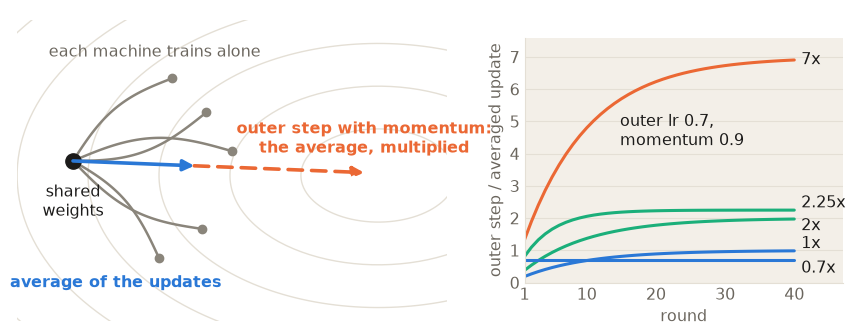

In [3]:
def outer_multiplier(lr, m, rounds=40):
    b, out = 0.0, []
    for _ in range(rounds):
        b = m * b + 1.0
        out.append(lr * (1.0 + m * b))
    return np.array(out)


SETTINGS = [(0.7, 0.9, "orange", "0.7 / 0.9 (default)"), (0.45, 0.8, "green", "0.45 / 0.8"), (0.2, 0.9, "green", "0.2 / 0.9"),
            (0.1, 0.9, "blue", "0.1 / 0.9"), (0.7, 0.0, "blue", "0.7 / 0")]


def draw_diloco(ax, t):
    ax.set_axis_off()
    fig = ax.figure
    a = fig.add_axes([0.02, 0.06, 0.50, 0.86])
    a.set_facecolor(t["panel"])
    a.set(xlim=(0, 10), ylim=(0, 6.2))
    a.axis("off")
    for r in (1.2, 2.3, 3.4, 4.5, 5.6, 6.7):  # level sets of a bowl whose minimum is at the right
        th = np.linspace(0, 2 * np.pi, 200)
        a.plot(8.4 + 1.5 * r * np.cos(th), 3.0 + 0.8 * r * np.sin(th), color=t["grid"], lw=1)
    start, ends = np.array([1.3, 3.3]), np.array([[3.6, 5.0], [4.4, 4.3], [5.0, 3.5], [4.3, 1.9], [3.3, 1.3]])
    for k, e in enumerate(ends):
        s = np.linspace(0, 1, 60)
        bend = np.array([-(e - start)[1], (e - start)[0]]) * 0.10 * (-1) ** k
        path = start + np.outer(s, e - start) + np.outer(np.sin(np.pi * s), bend)
        a.plot(path[:, 0], path[:, 1], color=t["grey"], lw=1.8)
        a.plot(*e, "o", ms=6, color=t["grey"])
    mean = ends.mean(0)
    arrow = dict(arrowstyle="-|>", mutation_scale=16, shrinkA=0, shrinkB=0)
    a.annotate("", mean, start, arrowprops=dict(color=t["blue"], lw=2.6, **arrow))
    big = start + 2.4 * (mean - start)
    a.annotate("", big, mean, arrowprops=dict(color=t["orange"], lw=2.6, ls=(0, (4, 2.5)), **arrow))
    a.plot(*start, "o", ms=11, color=t["ink"])
    a.text(start[0], start[1] - 0.45, "shared\nweights", ha="center", va="top", color=t["ink"])
    a.text(3.2, 5.45, "each machine trains alone", ha="center", color=t["muted"])
    a.text(2.3, 0.95, "average of the updates", ha="center", va="top", color=t["blue"], fontweight="bold")
    a.text(big[0], big[1] + 0.3, "outer step with momentum:\nthe average, multiplied", ha="center", va="bottom", color=t["orange"], fontweight="bold")
    b = fig.add_axes([0.61, 0.17, 0.37, 0.70])
    b.set_facecolor(t["panel"])
    rounds = np.arange(1, 41)
    for lr, m, c, name in SETTINGS:
        y = outer_multiplier(lr, m)
        b.plot(rounds, y, color=t[c], lw=2.2)
        lim = lr / (1 - m)  # the value the curve tends to
        b.annotate(f"{lim:g}x", (40, y[-1]), xytext=(5, {2.25: 5, 2.0: -5, 1.0: 5, 0.7: -6}.get(round(lim, 2), 0)), textcoords="offset points",
                   va="center", color=t["ink"])
    b.annotate("outer lr 0.7,\nmomentum 0.9", (14, outer_multiplier(0.7, 0.9)[13]), xytext=(4, -30), textcoords="offset points", color=t["ink"])
    b.set(xlim=(1, 47), ylim=(0, 7.6), xlabel="round", ylabel="outer step / averaged update")
    b.set_xticks([1, 10, 20, 30, 40])
    b.grid(axis="x", visible=False)


render("diloco_round", draw_diloco, size=(8.6, 3.5))

The left panel is a schematic, not data. The right panel assumes the averaged
update keeps a constant direction, so it is an upper bound on what a real run sees.

## 2. The symptom: the loss falls, one block does the work

**Setup.** Masked reconstruction in the style of VideoMAE (16 frames at 224 px,
tubelet 2, patch 16, mask ratio 0.9), a ViT-B encoder (width 768, depth 12) and a
depth-4 decoder, written from scratch with no pretrained weights, on an
unlabelled 218-hour subset of VoxCeleb2.

Every early run was ranked on reconstruction validation loss. This is the longest
one, on 16 machines.

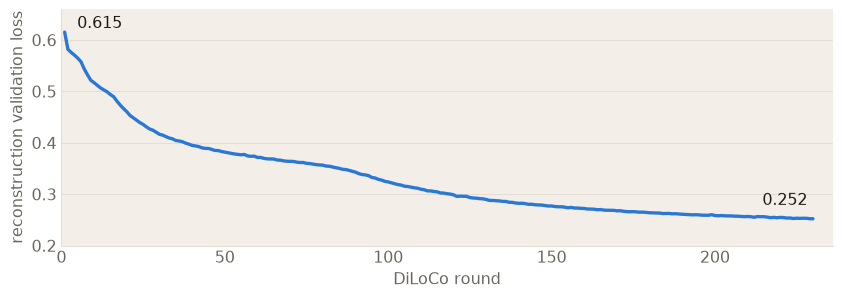

In [4]:
curves = pd.read_csv(DATA / "loss_curves.csv")
longest = curves[curves.run.str.contains("longest")].sort_values("round")


def draw(ax, t):
    ax.plot(longest["round"], longest.val_loss_mean, color=t["blue"], lw=2.4)
    a, b = longest.iloc[0], longest.iloc[-1]
    ax.annotate(f"{a.val_loss_mean:.3f}", (a["round"], a.val_loss_mean), xytext=(9, 3), textcoords="offset points", color=t["ink"])
    ax.annotate(f"{b.val_loss_mean:.3f}", (b["round"], b.val_loss_mean), xytext=(-4, 10), textcoords="offset points", ha="right", color=t["ink"])
    ax.set(xlabel="DiLoCo round", ylabel="reconstruction validation loss", xlim=(0, 236), ylim=(0.2, 0.66))
    ax.grid(axis="x", visible=False)


render("loss_curve", draw, size=(8.6, 3.2))

A block-skip test replaces one encoder block with the identity and measures how
much the held-out reconstruction error rises. Below: ten encoders trained for 20
rounds on one machine (seven settings, three of them with two seeds), and a
random initialisation.

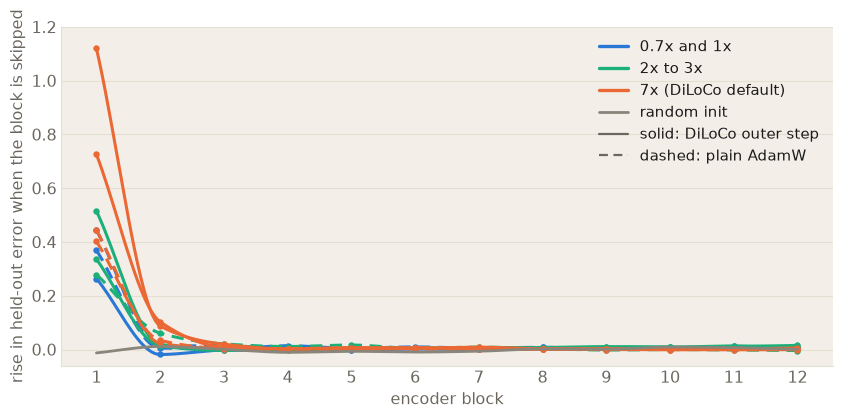

In [5]:
profile = pd.read_csv(DATA / "depth_profile.csv")
dose_arms = profile[profile.group == "dose"]
rand_prof = profile[profile.group == "reference"].sort_values("block")


def draw_profile(ax, t, col):
    for (mult, route, seed), g in dose_arms.groupby(["multiplier", "route", "seed"]):
        g = g.sort_values("block")
        xs, ys = smooth(g.block, g[col])
        ax.plot(xs, ys, color=t[level(mult)], lw=2.2, ls="-" if route == "diloco" else (0, (4, 2.5)))
        ax.plot(g.block, g[col], "o", ms=3.6, color=t[level(mult)])
    xs, ys = smooth(rand_prof.block, rand_prof[col])
    ax.plot(xs, ys, color=t["grey"], lw=2)
    ax.set_xticks(range(1, 13))
    ax.set_xlabel("encoder block")
    ax.grid(axis="x", visible=False)


def draw_skip(ax, t):
    draw_profile(ax, t, "skip_cost_mse")
    ax.set_ylabel("rise in held-out error when the block is skipped")
    ax.set_ylim(-0.06, 1.2)
    dose_legend(ax, t)


render("block_skip", draw_skip)

In [6]:
b1 = dose_arms[dose_arms.block == 1].skip_cost_mse
deep = dose_arms[dose_arms.block >= 4].skip_cost_mse
print(f"skipping block 1 costs {b1.min():.2f} to {b1.max():.2f}")
print(f"skipping any one of blocks 4 to 12 costs at most {deep.max():.3f}")
print(f"the same test on a random initialisation varies within +/-{rand_prof.skip_cost_mse.abs().max():.3f}")
long100 = profile[profile.arm.str.contains("100 rounds")].sort_values("block")
long100[["arm", "block", "skip_cost_mse"]].head(4)

skipping block 1 costs 0.26 to 1.12
skipping any one of blocks 4 to 12 costs at most 0.017
the same test on a random initialisation varies within +/-0.013


,arm,block,skip_cost_mse
12,"7x DiLoCo, 16 machines, 100 rounds",1,0.416
13,"7x DiLoCo, 16 machines, 100 rounds",2,0.163
14,"7x DiLoCo, 16 machines, 100 rounds",3,0.021
15,"7x DiLoCo, 16 machines, 100 rounds",4,0.014


Blocks 4 to 12 contribute nothing that this test can detect, at every setting.
After 100 rounds on 16 machines (table above) block 2 contributes as well, and
blocks 4 to 12 still do not.

## 3. The cause: the size of the update

Define `effective multiplier = outer_lr / (1 - momentum) x lr_mult` (section 1)
and reach the same value by two routes: through the outer step, or with plain
AdamW and a larger learning rate. First, the norm of the residual stream after
each block.

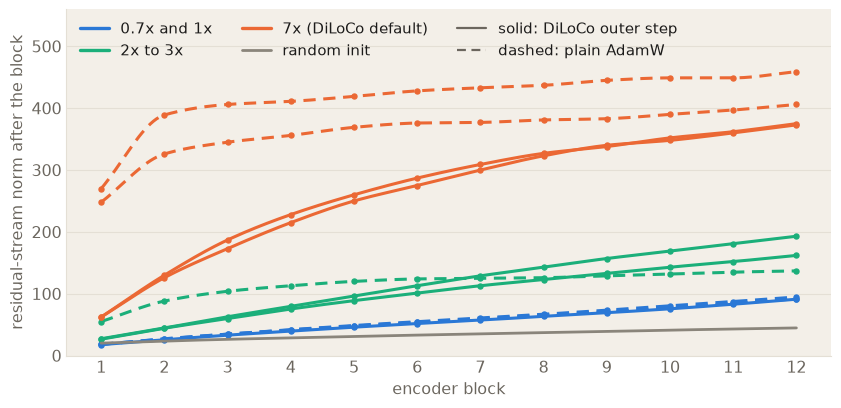

In [7]:
def draw_norm(ax, t):
    draw_profile(ax, t, "stream_norm")
    ax.set_ylabel("residual-stream norm after the block")
    ax.set_ylim(0, 560)
    dose_legend(ax, t, loc="upper left", ncol=3)


render("stream_norm", draw_norm)

Second, *motion R2* at the last block: a linear map from the frozen tokens to how
much each patch changes between frames. It measures whether the encoder keeps
information about motion.

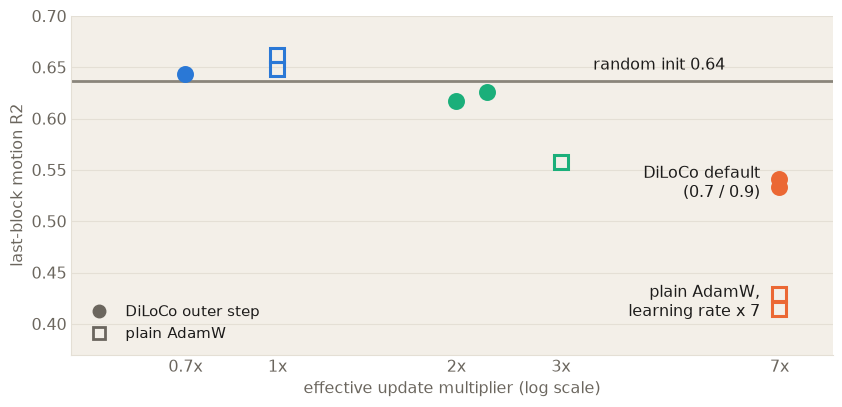

In [8]:
dose = pd.read_csv(DATA / "dose_response.csv")
runs = dose[dose.group == "dose"]
RAND = float(dose[dose.group == "reference"].l12_motion_r2.iloc[0])


def draw_dose(ax, t):
    ax.axhline(RAND, color=t["grey"], lw=2)
    ax.text(3.4, RAND + 0.007, f"random init {RAND:.2f}", color=t["ink"], va="bottom")
    for r in runs.itertuples():
        own = r.route == "diloco"
        ax.plot(r.multiplier, r.l12_motion_r2, "o" if own else "s", ms=10, mfc=t[level(r.multiplier)] if own else "none",
                mec=t[level(r.multiplier)], mew=2.2)
    ax.annotate("DiLoCo default\n(0.7 / 0.9)", (7, 0.537), xytext=(-14, 0), textcoords="offset points", ha="right", va="center", color=t["ink"])
    ax.annotate("plain AdamW,\nlearning rate x 7", (7, 0.421), xytext=(-14, 0), textcoords="offset points", ha="right", va="center", color=t["ink"])
    ax.legend(handles=[Line2D([], [], marker="o", ls="none", ms=9, color=t["muted"], label="DiLoCo outer step"),
                       Line2D([], [], marker="s", ls="none", ms=9, mfc="none", mew=2, color=t["muted"], label="plain AdamW")],
              loc="lower left", labelcolor=t["ink"])
    ax.set_xscale("log")
    ax.set_xticks([0.7, 1, 2, 3, 7], ["0.7x", "1x", "2x", "3x", "7x"])
    ax.set_xticks([], minor=True)
    ax.set(xlim=(0.45, 8.6), ylim=(0.37, 0.70), xlabel="effective update multiplier (log scale)", ylabel="last-block motion R2")
    ax.grid(axis="x", visible=False)


render("dose_response", draw_dose)

In [9]:
n12 = dose_arms[dose_arms.block == 12][["arm", "multiplier", "seed", "stream_norm"]]
runs[["arm", "multiplier", "outer_lr_momentum", "seed", "l12_motion_r2"]].merge(n12, on=["arm", "multiplier", "seed"]).rename(
    columns={"stream_norm": "stream_norm_block12"})

,arm,multiplier,outer_lr_momentum,seed,l12_motion_r2,stream_norm_block12
0,0.7x DiLoCo,0.70,0.7/0.0,0.0,0.643,91.2
1,1x plain AdamW,1.00,NaN,0.0,0.648,91.9
2,1x plain AdamW,1.00,NaN,1.0,0.662,94.8
3,2x DiLoCo,2.00,0.2/0.9,0.0,0.617,193.0
4,2.25x DiLoCo,2.25,0.45/0.8,0.0,0.626,162.0
5,3x plain AdamW,3.00,NaN,0.0,0.558,137.0
6,7x DiLoCo,7.00,0.7/0.9,0.0,0.533,373.0
7,7x DiLoCo,7.00,0.7/0.9,1.0,0.541,375.0
8,7x plain AdamW,7.00,NaN,0.0,0.414,459.0
9,7x plain AdamW,7.00,NaN,1.0,0.429,406.0


At 0.7x and 1x the stream norm ends near 90 and motion R2 stays at the level of a
random initialisation (0.64 to 0.66). At 7x the norm ends between 370 and 460 and
motion R2 falls to 0.53 to 0.54 with the DiLoCo outer step, and to 0.41 to 0.43
with plain AdamW at seven times the learning rate.

Plain AdamW at 7x is affected more than DiLoCo at 7x. So the outer momentum is not
what does it: the size of the update is.

## 4. The correction, and what it bought

Every later run keeps the effective multiplier at 1x. Two downstream checks were
run on encoders trained that way.

**Frozen probe.** A small attentive probe is trained on frozen layer-6 features to
predict valence and arousal on AFEW-VA, 3 seeds, next to a random-initialisation
control run in the same job. Rows 3 and 4 are public pretrained models, for scale.

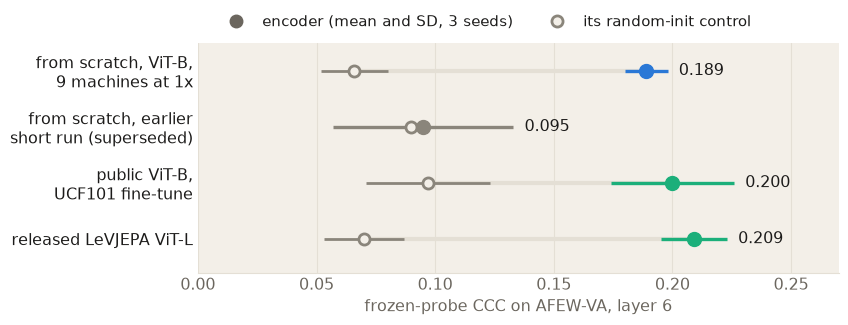

In [10]:
ladder = pd.read_csv(DATA / "probe_ladder.csv")
LADDER_NAME = {1: "from scratch, ViT-B,\n9 machines at 1x", 2: "from scratch, earlier\nshort run (superseded)",
               3: "public ViT-B,\nUCF101 fine-tune", 4: "released LeVJEPA ViT-L"}


def draw_ladder(ax, t):
    rows = ladder.sort_values("rung", ascending=False).reset_index(drop=True)
    for i, r in rows.iterrows():
        c = t["blue"] if r.rung == 1 else t["green"] if r.kind == "reference" else t["grey"]
        ax.plot([r.control_ccc, r.layer6_ccc], [i, i], color=t["grid"], lw=3, zorder=1)
        ax.errorbar(r.control_ccc, i, xerr=r.control_sd, fmt="o", ms=8, mfc=t["panel"], mec=t["grey"], mew=2, ecolor=t["grey"], elinewidth=2)
        ax.errorbar(r.layer6_ccc, i, xerr=r.layer6_sd, fmt="o", ms=10, color=c, ecolor=c, elinewidth=2.4)
        ax.annotate(f"{r.layer6_ccc:.3f}", (r.layer6_ccc + r.layer6_sd, i), xytext=(8, 0), textcoords="offset points", va="center", color=t["ink"])
    ax.set_yticks(range(len(rows)), [LADDER_NAME[k] for k in rows.rung])
    ax.tick_params(axis="y", labelcolor=t["ink"])
    ax.legend(handles=[Line2D([], [], marker="o", ls="none", ms=9, color=t["muted"], label="encoder (mean and SD, 3 seeds)"),
                       Line2D([], [], marker="o", ls="none", ms=8, mfc=t["panel"], mew=2, color=t["grey"], label="its random-init control")],
              loc="lower center", bbox_to_anchor=(0.45, 1.0), ncol=2, labelcolor=t["ink"])
    ax.set(xlim=(0, 0.27), ylim=(-0.6, len(rows) - 0.5), xlabel="frozen-probe CCC on AFEW-VA, layer 6")
    ax.grid(axis="y", visible=False)
    ax.spines["left"].set_visible(False)


render("probe_ladder", draw_ladder, size=(8.6, 3.5))

In [11]:
ladder[["rung", "checkpoint", "kind", "layer6_ccc", "layer6_sd", "control_ccc", "control_sd", "diff"]]

,rung,checkpoint,kind,layer6_ccc,layer6_sd,control_ccc,control_sd,diff
0,1,from-scratch 9-node DiLoCo ViT-B,project,0.189,0.009,0.066,0.014,0.123
1,2,"overfit-50, seed-42 run (superseded)",project,0.095,0.038,0.090,0.025,0.004
2,3,"public VideoMAE V2 ViT-B, UCF101 fine-tune (ma...",reference,0.200,0.026,0.097,0.026,0.103
3,4,"released LeVJEPA ViT-L, fine-tuned (layer 12 o...",reference,0.209,0.014,0.070,0.017,0.140


The from-scratch ViT-B trained on 9 machines at 1x reads 0.189 against 0.066 for
its control. The two public pretrained models read 0.200 and 0.209 on the same
probe. Three seeds, one layer, a small probe; the controls are unseeded, so
differences are read within a row.

**Paired fine-tuning test ("the gate").** Fine-tune the encoder and a random
initialisation with the same 10 seeds and report the paired difference in CCC with
a 95% interval. The run: 14 machines, DiLoCo at outer learning rate 0.1 and
momentum 0.9 (1x), a smaller encoder (depth 7, about 34M parameters) trained with
the LeVJEPA objective.

The gate had a seeding bug until 2026-11-01: seeds within one job could repeat, so
intervals computed before that date are too narrow. The figure shows the earlier
snapshots as points without intervals, and the two snapshots re-run after the fix
with their intervals.

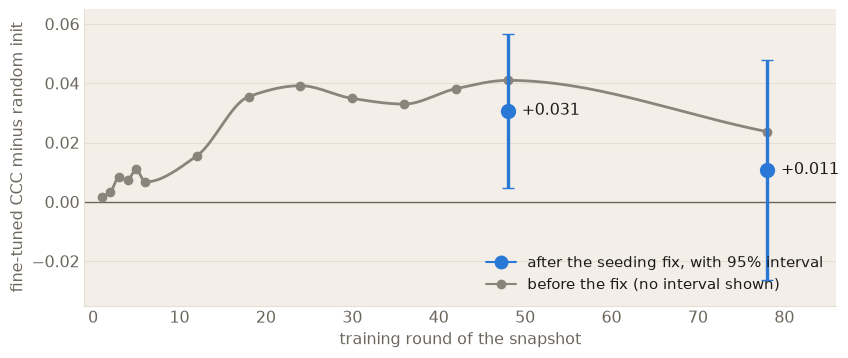

In [12]:
gate = pd.read_csv(DATA / "gate.csv")
g_long = gate[gate.series == "long"]
before, after = g_long[g_long.seeding_fix == "before"].sort_values("round"), g_long[g_long.seeding_fix == "after"].sort_values("round")


def draw_gate(ax, t):
    ax.axhline(0, color=t["muted"], lw=1)
    xs, ys = smooth(before["round"], before.diff_ccc)
    ax.plot(xs, ys, color=t["grey"], lw=2)
    ax.plot(before["round"], before.diff_ccc, "o", ms=6, color=t["grey"])
    ax.errorbar(after["round"], after.diff_ccc, yerr=[after.diff_ccc - after.ci_lo, after.ci_hi - after.diff_ccc],
                fmt="o", ms=10, color=t["blue"], ecolor=t["blue"], elinewidth=2.4, capsize=4, zorder=3)
    for r in after.itertuples():
        ax.annotate(f"{r.diff_ccc:+.3f}", (r.round, r.diff_ccc), xytext=(10, 0), textcoords="offset points", va="center", color=t["ink"])
    ax.legend(handles=[Line2D([], [], marker="o", ms=9, color=t["blue"], label="after the seeding fix, with 95% interval"),
                       Line2D([], [], marker="o", ms=6, color=t["grey"], label="before the fix (no interval shown)")],
              loc="lower right", labelcolor=t["ink"])
    ax.set(xlim=(-1, 86), ylim=(-0.035, 0.065), xlabel="training round of the snapshot", ylabel="fine-tuned CCC minus random init")
    ax.grid(axis="x", visible=False)


render("gate_curve", draw_gate, size=(8.6, 3.8))

In [13]:
after[["round", "verdict", "encoder_ccc", "random_init_ccc", "diff_ccc", "ci_lo", "ci_hi"]]

,round,verdict,encoder_ccc,random_init_ccc,diff_ccc,ci_lo,ci_hi
2,48.0,PASS,0.089,0.058,0.031,0.005,0.057
3,78.0,UNRESOLVED,0.069,0.058,0.011,-0.026,0.048


At round 48 the encoder reaches a CCC of 0.089 against 0.058 for a random
initialisation: +0.031, 95% interval [+0.005, +0.057]. At round 78 the difference
is +0.011 and the interval includes zero. For scale, the released pretrained ViT-L
scores about +0.26 on this gate. It is one training run.

## 5. What is still open: the deep blocks

Lowering the update removes the norm growth and the loss of motion information.
It does not make blocks 4 to 12 contribute. Ten variants of the recipe were tried
for that and none changes it (appendix A). A 3-block encoder trained with the same
recipe reaches the same validation loss as the 12-block one: 0.516 and 0.518
against 0.524 and 0.525 (two seeds each). So the next thing to change is the
objective, not the optimiser.

## 6. Continued pretraining of a released model

Start from the released LeVJEPA ViT-L, continue its self-supervised pretraining on
the same unlabelled face video for about 1,080 encoder steps, then fine-tune on
AFEW-VA. Thirty seeds per arm, one job per seed.

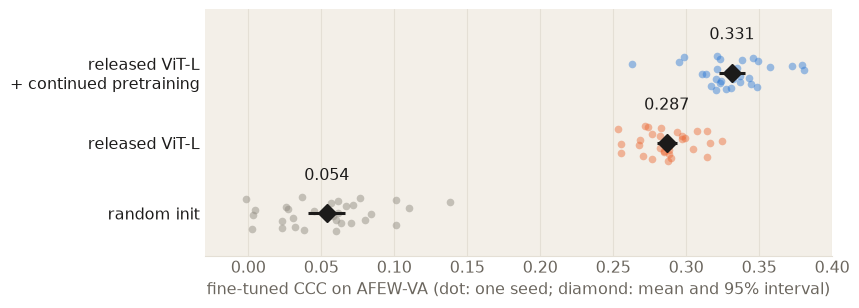

In [14]:
cpt = pd.read_csv(DATA / "continued_pretraining.csv")
ORDER = ["random", "hf", "cpt"]
NAME = {"random": "random init", "hf": "released ViT-L", "cpt": "released ViT-L\n+ continued pretraining"}
half = lambda x: 2.045 * x.std(ddof=1) / np.sqrt(len(x))  # t(0.975, 29)


def draw_cpt(ax, t):
    for i, arm in enumerate(ORDER):
        v = cpt[cpt.arm == arm].sort_values("seed").ccc.to_numpy()
        c = t["blue"] if arm == "cpt" else t["orange"] if arm == "hf" else t["grey"]
        jitter = ((np.arange(len(v)) * 0.618) % 1 - 0.5) * 0.5
        ax.plot(v, i + jitter, "o", ms=5.5, color=c, alpha=0.45, mew=0)
        ax.errorbar(v.mean(), i, xerr=half(v), fmt="D", ms=9, color=t["ink"], ecolor=t["ink"], elinewidth=2.2, zorder=3)
        ax.text(v.mean(), i + 0.42, f"{v.mean():.3f}", ha="center", va="bottom", color=t["ink"])
    ax.set_yticks(range(3), [NAME[a] for a in ORDER])
    ax.tick_params(axis="y", labelcolor=t["ink"])
    ax.set(ylim=(-0.6, 2.9), xlim=(-0.03, 0.4), xlabel="fine-tuned CCC on AFEW-VA (dot: one seed; diamond: mean and 95% interval)")
    ax.grid(axis="y", visible=False)
    ax.spines["left"].set_visible(False)


render("continued_pretraining", draw_cpt, size=(8.6, 3.3))

In [15]:
p = cpt.pivot(index="seed", columns="arm", values="ccc")
d = p.cpt - p.hf
se = np.sqrt(p.cpt.var(ddof=1) / 30 + p.hf.var(ddof=1) / 30)
print(f"paired gain {d.mean():+.3f} [{d.mean() - half(d):+.3f}, {d.mean() + half(d):+.3f}], n = 30")
print(f"unpaired check {d.mean():+.3f} [{d.mean() - 2.0 * se:+.3f}, {d.mean() + 2.0 * se:+.3f}]")
print("seeds with a higher CCC after continued pretraining:", int((d > 0).sum()), "of 30")
cpt.groupby("arm")[["ccc", "ccc_valence", "ccc_arousal"]].mean().loc[ORDER]

paired gain +0.045 [+0.036, +0.053], n = 30
unpaired check +0.045 [+0.034, +0.056]
seeds with a higher CCC after continued pretraining: 29 of 30


,ccc,ccc_valence,ccc_arousal
arm,,,
random,0.054,0.090,0.018
hf,0.287,0.090,0.483
cpt,0.331,0.176,0.487


Continued pretraining raises CCC from 0.287 to 0.331; 29 of 30 seeds improve. The
gain is in valence (0.090 to 0.176); arousal is unchanged. Scope: 48 held-out
actors, 102 clips, one identity split. The snapshot was chosen by a small frozen
probe among five runs at four learning rates.

## 7. The system

The pool is 113 single-GPU workstations in five hardware tiers, joined by 1 GbE and
shared with teaching. Each worker is one GPU process that trains locally and
communicates once per round. A watcher advances every run each minute, restarts
dead jobs once, and keeps every job off the machines on weekdays from 08:00 to
20:00. Details and the throughput measurement are in appendix D.

## 8. Limits

- Sections 2 and 3 and appendices A and B rest on 20-round, single-machine
  encoders, mostly one seed per setting. The dose-response was pre-registered as a
  rank test (Spearman at most -0.8, p < 0.05). Four doses survive for the stricter
  readout, too few for that threshold: the test gives rho = -0.80, p = 0.17.
- The frozen probe of section 4 is 3 seeds on one layer. The ViT-B encoders have
  not been through the paired gate.
- The gate result of section 4 is one training run, and the difference is no
  longer resolved at round 78.
- All downstream numbers are on AFEW-VA.

# Appendix

## A. Ten variants of the recipe

Cost of skipping block 1 and largest cost among blocks 4 to 12, for each variant of
the 7x recipe. LayerScale at 1e-4 flattens the profile only because the encoder
stops writing to the stream (stream norm 20).

In [16]:
fix = profile[profile.group == "fix"]
pd.DataFrame({
    "block 1 cost": fix[fix.block == 1].set_index("arm").skip_cost_mse,
    "max cost, blocks 4 to 12": fix[fix.block >= 4].groupby("arm").skip_cost_mse.max(),
    "stream norm, block 12": fix[fix.block == 12].set_index("arm").stream_norm,
}).round(3)

,block 1 cost,"max cost, blocks 4 to 12","stream norm, block 12"
arm,,,
fix: 4 register tokens,1.000,0.019,383.0
fix: LayerNorm scaling,0.777,0.007,210.0
fix: LayerNorm scaling + embedding LayerNorm,0.228,0.009,215.0
fix: LayerScale init 1e-4,0.002,0.025,20.5
fix: decoder depth 1,0.552,0.004,403.0
fix: deep supervision,1.000,0.003,387.0
fix: embedding LayerNorm,0.110,0.006,366.0
fix: lr_mult 0.5,1.250,0.017,297.0
fix: mask ratio 0.75,0.568,0.014,353.0


## B. A stricter motion readout

The motion readout of section 3 splits train and test by **token**, so tokens of
one clip sit on both sides. This version splits by **clip window**. It was run on a
second batch of encoders (0.7x to 3x; the 7x checkpoints of the first batch were no
longer stored).

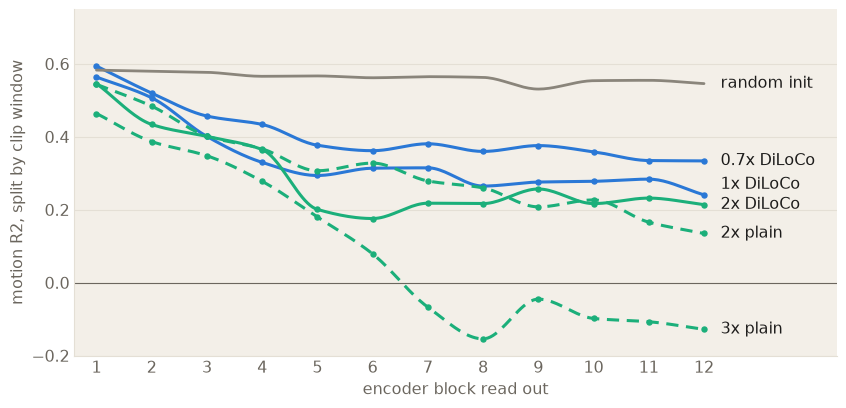

In [17]:
motion = pd.read_csv(DATA / "motion_by_layer.csv")
batch2 = motion[(motion.group == "dose2") & (motion.layer >= 1)]
rand2 = motion[(motion.group == "reference") & (motion.layer >= 1)]


def draw_motion(ax, t, kind="window_grouped"):
    ends = []
    for (mult, route), g in batch2[batch2.readout == kind].groupby(["multiplier", "route"]):
        g = g.sort_values("layer")
        xs, ys = smooth(g.layer, g.motion_r2)
        ax.plot(xs, ys, color=t[level(mult)], lw=2.2, ls="-" if route == "diloco" else (0, (4, 2.5)))
        ax.plot(g.layer, g.motion_r2, "o", ms=3.6, color=t[level(mult)])
        ends.append((g.motion_r2.iloc[-1], f"{mult:g}x {'DiLoCo' if route == 'diloco' else 'plain'}"))
    r = rand2[rand2.readout == kind].drop_duplicates("layer", keep="last").sort_values("layer")
    xs, ys = smooth(r.layer, r.motion_r2)
    ax.plot(xs, ys, color=t["grey"], lw=2)
    ends.append((r.motion_r2.iloc[-1], "random init"))
    y_lab = None
    for v, name in sorted(ends):
        y_lab = v if y_lab is None else max(v, y_lab + 0.055)
        ax.annotate(name, (12, v), xytext=(12.3, y_lab), va="center", color=t["ink"])
    ax.axhline(0, color=t["muted"], lw=0.8)
    ax.set_xticks(range(1, 13))
    ax.set(xlim=(0.6, 14.4), ylim=(-0.2, 0.75), xlabel="encoder block read out", ylabel="motion R2, split by clip window")
    ax.grid(axis="x", visible=False)


render("motion_by_layer", draw_motion)

In [18]:
lvm = pd.read_csv(DATA / "loss_vs_motion.csv")
lvm[["arm", "rounds", "final_val_loss", "l1_motion_r2_grouped", "l12_motion_r2_grouped", "l12_motion_r2_token"]]

,arm,rounds,final_val_loss,l1_motion_r2_grouped,l12_motion_r2_grouped,l12_motion_r2_token
0,"2x plain, 1 node, 60 rounds",60,0.422,0.637,0.393,0.621
1,"1x plain average, 9 nodes, 60 rounds",60,0.432,0.654,0.494,0.645
2,3x plain AdamW,20,0.514,0.464,-0.128,0.549
3,2x plain AdamW,20,0.518,0.544,0.135,0.609
4,0.7x DiLoCo,20,0.533,0.594,0.334,0.647
5,2x DiLoCo,20,0.543,0.546,0.214,0.619
6,1x DiLoCo,20,0.570,0.564,0.241,0.635


Motion information is highest at block 1 and decreases with depth in every trained
encoder, faster at a larger update: the last block reads 0.33 at 0.7x, 0.24 at 1x,
0.21 and 0.14 at 2x, and -0.13 at 3x. A random initialisation stays near 0.55. The
9-machine 1x encoder of section 4 (60 rounds, table above) holds up best: 0.65 at
block 1 and 0.49 at block 12. One seed per setting, 48 windows.

Validation loss does not follow this ordering:

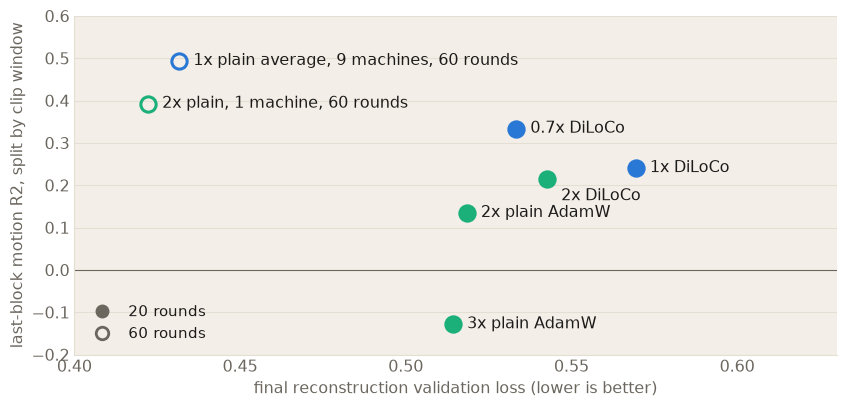

In [19]:
def draw_lvm(ax, t):
    for r in lvm.itertuples():
        short = r.rounds == 20
        ax.plot(r.final_val_loss, r.l12_motion_r2_grouped, "o", ms=11, mfc=t[level(r.multiplier)] if short else "none",
                mec=t[level(r.multiplier)], mew=2.2)
        xy = (10, -12) if (r.multiplier == 2 and r.route == "diloco") else (10, 0)
        name = r.arm.replace("nodes", "machines").replace("node", "machine")
        ax.annotate(name, (r.final_val_loss, r.l12_motion_r2_grouped), xytext=xy, textcoords="offset points", va="center", color=t["ink"])
    ax.axhline(0, color=t["muted"], lw=0.8)
    ax.legend(handles=[Line2D([], [], marker="o", ls="none", ms=9, color=t["muted"], label="20 rounds"),
                       Line2D([], [], marker="o", ls="none", ms=9, mfc="none", mew=2, color=t["muted"], label="60 rounds")],
              loc="lower left", labelcolor=t["ink"])
    ax.set(xlim=(0.40, 0.63), ylim=(-0.2, 0.6), xlabel="final reconstruction validation loss (lower is better)",
           ylabel="last-block motion R2, split by clip window")
    ax.grid(axis="x", visible=False)


render("loss_vs_motion", draw_lvm)

In [20]:
short = lvm[lvm.rounds == 20]
print("rank correlation between loss and readout, five 20-round encoders:",
      round(short.final_val_loss.rank().corr(short.l12_motion_r2_grouped.rank()), 2))

rank correlation between loss and readout, five 20-round encoders: 0.7


Among the five 20-round encoders, the one with the lowest loss (3x, 0.514) has the
lowest readout (-0.13). Five points: a description, not a test.

## C. A second collapse, and its fix

The small LeVJEPA encoder had its own failure. With its regulariser (SIGReg)
computed on batches of 16, the effective rank of its final token falls to about 1.2
within one round, and a speaker-identity probe (118 speakers) falls below a random
initialisation. Pooling the regulariser over a batch of 256 removes it.

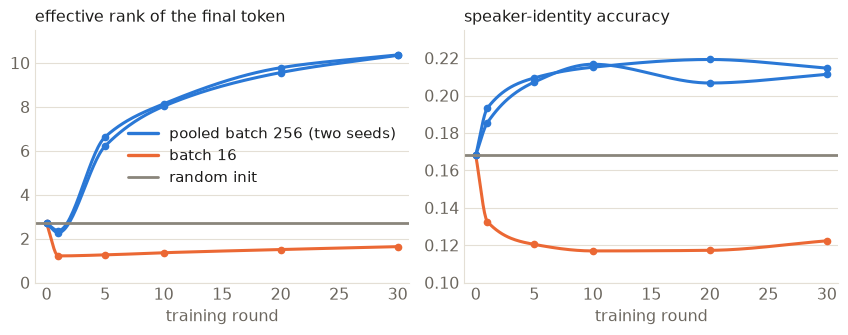

In [21]:
fixc = pd.read_csv(DATA / "collapse_fix.csv")
final = fixc[fixc.layer == "final"]


def draw_fix(ax, t):
    ax.set_axis_off()
    fig = ax.figure
    axes = [fig.add_subplot(1, 2, 1), fig.add_subplot(1, 2, 2)]
    for a, col, title in zip(axes, ["effective_rank", "speaker_acc"], ["effective rank of the final token", "speaker-identity accuracy"]):
        for (arm, seed), g in final.groupby(["arm", "seed"]):
            g = g.sort_values("round")
            c = t["blue"] if "256" in arm else t["orange"]
            xs, ys = smooth(g["round"], g[col])
            a.plot(xs, ys, color=c, lw=2.2)
            a.plot(g["round"], g[col], "o", ms=4.5, color=c)
        r0 = final[final["round"] == 0][col].iloc[0]
        a.axhline(r0, color=t["grey"], lw=2)
        a.set_xlabel("training round")
        a.set_title(title, fontsize=11.5, color=t["ink"], loc="left")
        a.set_xlim(-1, 31)
        a.grid(axis="x", visible=False)
    axes[0].set_ylim(0, 11.5)
    axes[1].set_ylim(0.1, 0.235)
    axes[0].legend(handles=[Line2D([], [], color=t["blue"], lw=2.4, label="pooled batch 256 (two seeds)"),
                            Line2D([], [], color=t["orange"], lw=2.4, label="batch 16"),
                            Line2D([], [], color=t["grey"], lw=2, label="random init")], loc="center right", labelcolor=t["ink"])


render("collapse_fix", draw_fix, size=(8.6, 3.6))

In [22]:
final.pivot_table(index=["arm", "seed"], columns="round", values=["effective_rank", "speaker_acc"]).round(3)

effective_rank                              \
round                                       0      1      5      10     20   
arm                        seed                                              
SIGReg batch 16 (baseline) 0             2.701  1.217  1.263  1.362  1.508   
pooled SIGReg batch 256    0             2.701  2.367  6.631  8.137  9.783   
                           1             2.701  2.272  6.215  8.027  9.563   

                                        speaker_acc                       \
round                                30          0      1      5      10   
arm                        seed                                            
SIGReg batch 16 (baseline) 0      1.639       0.168  0.133  0.120  0.117   
pooled SIGReg batch 256    0     10.366       0.168  0.186  0.207  0.217   
                           1     10.348       0.168  0.193  0.209  0.215   

                                               
round                               20     30  
arm                        seed                
SIGReg batch 16 (baseline) 0     0.117  0.122  
pooled SIGReg batch 256    0     0.207  0.211  
                           1     0.219  0.215

With the pooled batch the rank reaches 10.4 and speaker identity 0.21, on both
seeds, against 2.7 and 0.168 at a random initialisation. The rank fix alone did not
improve valence and arousal: on the gate, these encoders scored about 0.03 below a
random initialisation (measured before the seeding fix).

## D. The system in more detail

Synchronous multi-node training was measured first.

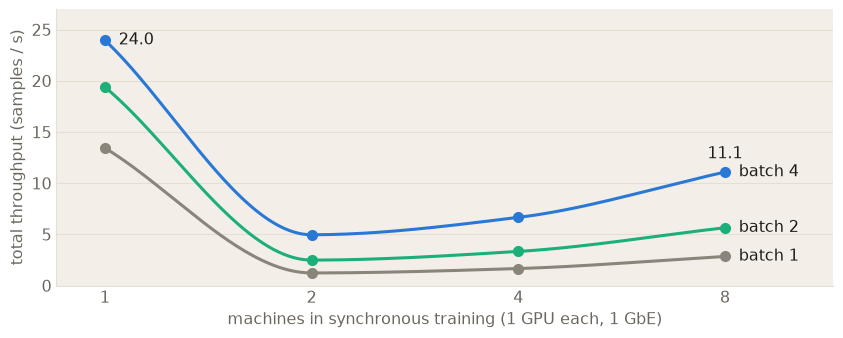

In [23]:
sweep = pd.read_csv(DATA / "throughput_sweep.csv")
scaling = sweep[sweep.run_tag.str.match(r"p1-n\d-b\d$")].sort_values(["local_batch", "world_size"])


def draw_tp(ax, t):
    for (b, g), c in zip(scaling.groupby("local_batch"), ["grey", "green", "blue"]):
        xs, ys = smooth(g.world_size, g.samples_per_s_global, logx=True)
        ax.plot(xs, ys, color=t[c], lw=2.2)
        ax.plot(g.world_size, g.samples_per_s_global, "o", color=t[c], ms=7)
        ax.annotate(f"batch {b}", (8, g.samples_per_s_global.iloc[-1]), xytext=(10, 0), textcoords="offset points", va="center", color=t["ink"])
    b4 = scaling[scaling.local_batch == 4].set_index("world_size").samples_per_s_global
    ax.annotate(f"{b4[1]:.1f}", (1, b4[1]), xytext=(10, 0), textcoords="offset points", va="center", color=t["ink"])
    ax.annotate(f"{b4[8]:.1f}", (8, b4[8]), xytext=(0, 10), textcoords="offset points", ha="center", color=t["ink"])
    ax.set_xscale("log", base=2)
    ax.set_xticks([1, 2, 4, 8], ["1", "2", "4", "8"])
    ax.set_xticks([], minor=True)
    ax.set(xlim=(0.85, 11.5), ylim=(0, 27), xlabel="machines in synchronous training (1 GPU each, 1 GbE)", ylabel="total throughput (samples / s)")
    ax.grid(axis="x", visible=False)


render("throughput_scaling", draw_tp, size=(8.6, 3.6))

At batch 4, eight machines exchanging gradients every step process 11.1 samples/s;
one machine alone processes 24.0. That is why training is DiLoCo.

- **One round.** Assign shards (each held by exactly one machine), run local steps,
  wait for a quorum or a grace deadline, merge (drop stale and non-finite updates,
  weighted average, Nesterov outer step), sync the new master.
- **Watcher.** A one-minute tick advances every run's state machine and runs six
  detectors: dead job, stalled job, foreign GPU process, quota, drained node, NaN.
  A dead job is resubmitted once; a second death escalates.
- **Class-hours gate.** No job runs on weekdays from 08:00 to 20:00, and a job is
  refused if any part of its walltime would overlap that window. Enforced in the
  job scripts, in a shim in front of the scheduler commands, and in the watcher.
- **Gate seeding.** The gate had a seeding bug until 2026-11-01: seeds within one
  job could repeat, so intervals computed before that date are too narrow.

## Data for the figures of the page

In [24]:
r4 = lambda v: [round(float(x), 4) for x in v]
prof = lambda g: {c: r4(g.sort_values("block")[c]) for c in ["skip_cost_mse", "stream_norm"]}
name = lambda mult, route: f"{mult:g}x {'DiLoCo' if route == 'diloco' else 'plain AdamW'}"
arms = [{"label": name(mult, route), "multiplier": mult, "route": route, "seed": int(seed), **prof(g)}
        for (mult, route, seed), g in dose_arms.groupby(["multiplier", "route", "seed"])]
fixes = [{"label": arm.replace("fix: ", ""), **prof(g)} for arm, g in fix.groupby("arm", sort=False)]
mot = motion[(motion.readout == "window_grouped") & (motion.layer >= 1)]
mot_arms = [{"label": name(mult, route) if grp == "dose2" else "1x, 9 machines, 60 rounds", "multiplier": mult, "route": route, "long": grp != "dose2",
             "r2": r4(g.sort_values("layer").motion_r2)}
            for (grp, mult, route), g in mot[mot.group.isin(["dose2", "long2"]) & ~mot.arm.str.contains("1 node")].groupby(["group", "multiplier", "route"])]
page = {
    "loss": {"round": [int(v) for v in longest["round"]], "val": r4(longest.val_loss_mean)},
    "profile": arms, "random": prof(rand_prof), "long100": prof(long100), "fixes": fixes,
    "dose": [{"multiplier": r.multiplier, "route": r.route, "r2": r.l12_motion_r2} for r in runs.itertuples()], "dose_random": RAND,
    "motion": mot_arms, "motion_random": r4(rand2[rand2.readout == "window_grouped"].drop_duplicates("layer", keep="last").sort_values("layer").motion_r2),
    "ladder": [{"rung": int(r.rung), "kind": r.kind, "ccc": r.layer6_ccc, "sd": r.layer6_sd, "ctrl": r.control_ccc, "ctrl_sd": r.control_sd} for r in ladder.itertuples()],
    "gate": {k: [{"round": int(r.round), "diff": r.diff_ccc, "lo": r.ci_lo, "hi": r.ci_hi} for r in g.itertuples()] for k, g in (("before", before), ("after", after))},
    "cpt": {a: r4(cpt[cpt.arm == a].sort_values("seed").ccc) for a in ORDER},
    "rank": [{"pooled": "256" in arm, "round": [int(v) for v in g.sort_values("round")["round"]], "rank": r4(g.sort_values("round").effective_rank),
              "spk": r4(g.sort_values("round").speaker_acc)} for (arm, seed), g in final.groupby(["arm", "seed"])],
    "throughput": [{"batch": int(b), "machines": [int(v) for v in g.world_size], "sps": r4(g.samples_per_s_global)} for b, g in scaling.groupby("local_batch")],
}
(ASSETS / "data.js").write_text("/* Generated by notebooks/stern_overview.ipynb from the tables in data/. Do not edit. */\n"
                                f"window.STERN = {json.dumps(page, ensure_ascii=False)};\n")
print(len(sorted(ASSETS.glob("*.svg"))), "SVG files and data.js written to assets/")

24 SVG files and data.js written to assets/
